Linear Regression

Objective: EDA real estate data and prediction using linear regression
dataset:realestate.csv
ref:N/A

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

pd.options.display.float_format='{:,.2f}'.format
data=pd.read_csv('realestate.csv')
print('Dataset size:', data.shape)
data.head()


Dataset size: (414, 8)


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,"2,012.92",32.00,84.88,10,24.98,121.54,37.90
1,2,"2,012.92",19.50,306.59,9,24.98,121.54,42.20
2,3,"2,013.58",13.30,561.98,5,24.99,121.54,47.30
3,4,"2,013.50",13.30,561.98,5,24.99,121.54,54.80
4,5,"2,012.83",5.00,390.57,5,24.98,121.54,43.10


In [7]:
#renanme column
data.columns=['No','TrxDate','Houseage','MRT_distance','NoStores','Long','Lat','Price']
data.head()

,No,TrxDate,Houseage,MRT_distance,NoStores,Long,Lat,Price
0,1,"2,012.92",32.00,84.88,10,24.98,121.54,37.90
1,2,"2,012.92",19.50,306.59,9,24.98,121.54,42.20
2,3,"2,013.58",13.30,561.98,5,24.99,121.54,47.30
3,4,"2,013.50",13.30,561.98,5,24.99,121.54,54.80
4,5,"2,012.83",5.00,390.57,5,24.98,121.54,43.10


In [8]:
#drop column
data.drop(['No','TrxDate','Long','Lat'],axis=1,inplace=True)
data.head()

,Houseage,MRT_distance,NoStores,Price
0,32.00,84.88,10,37.90
1,19.50,306.59,9,42.20
2,13.30,561.98,5,47.30
3,13.30,561.98,5,54.80
4,5.00,390.57,5,43.10


In [9]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Houseage      414 non-null    float64
 1   MRT_distance  414 non-null    float64
 2   NoStores      414 non-null    int64  
 3   Price         414 non-null    float64
dtypes: float64(3), int64(1)
memory usage: 13.1 KB


Correlation

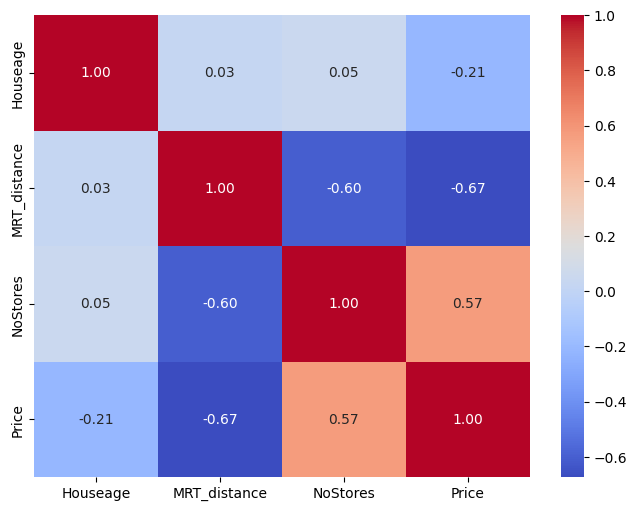

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
sns.heatmap(data=data.corr(),annot=True,fmt='.2f',cmap='coolwarm')
plt.show()

In [11]:
corr_rank=data.corr()
corr_rank["Price"].sort_values(ascending=False)

Price           1.00
NoStores        0.57
Houseage       -0.21
MRT_distance   -0.67
Name: Price, dtype: float64

Split Train Test

In [ ]:
stt=np.random.rand(len(data))<0.8
train=data[stt]
test=data[~stt]#~ means opposite of upper variable
print(train.shape)
train.head()

(334, 4)


,Houseage,MRT_distance,NoStores,Price
0,32.00,84.88,10,37.90
1,19.50,306.59,9,42.20
2,13.30,561.98,5,47.30
3,13.30,561.98,5,54.80
5,7.10,"2,175.03",3,32.10


In [14]:
print(test.shape)
test.head()

(86, 4)


,Houseage,MRT_distance,NoStores,Price
5,7.10,"2,175.03",3,32.10
10,34.80,405.21,1,41.40
23,10.10,279.17,7,47.90
28,19.20,557.48,4,47.00
33,16.50,323.65,6,49.30


Modelling 1: NoStores

Coefficient:  [[2.64635767]]
Intercept:    [27.21285916]


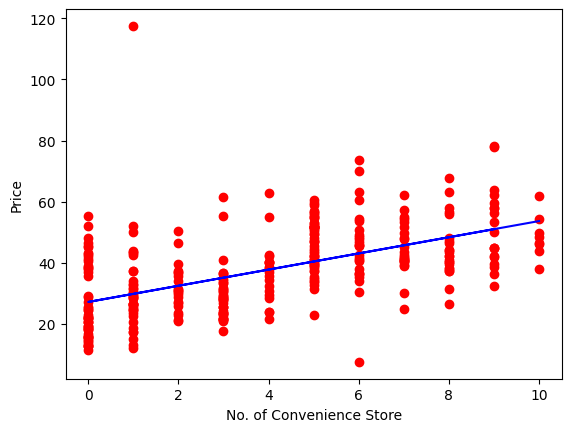

In [15]:
#using sklearn package to model data
from sklearn import linear_model
regr_en=linear_model.LinearRegression()
train_x1=np.asanyarray(train[['NoStores']])
train_y1=np.asanyarray(train[["Price"]])
regr_en.fit(train_x1,train_y1)
print("Coefficient: ",regr_en.coef_)
print("Intercept:   ",regr_en.intercept_)
#plot line into scatter plot
plt.scatter(train.NoStores,train.Price,color="red")
plt.plot(train_x1,regr_en.coef_[0][0]*train_x1+regr_en.intercept_[0],'-b')
plt.xlabel("No. of Convenience Store")
plt.ylabel("Price")
plt.show()

In [16]:
#check model accuracy
from sklearn.metrics import r2_score

test_x1=np.asanyarray(test[["NoStores"]])
test_y1=np.asanyarray(test[["Price"]])
test_y1_=regr_en.predict(test_x1)
en_mae=np.mean(np.absolute(test_y1_ - test_y1))
en_mse=np.mean((test_y1_ - test_y1)**2)
en_r2=r2_score(test_y1_,test_y1_)
print("Mean absolute error: %.2f" % en_mae)
print("Residential sum of squares(MSE): %.2f" % en_mse)
print("R2-score: %.2f" % en_r2)
print("Root mean squared error(RMSE): %.2f" % en_mse**0.5)


Mean absolute error: 7.34
Residential sum of squares(MSE): 91.10
R2-score: 1.00
Root mean squared error(RMSE): 9.54


In [24]:
#using model 1 for prediction
new_nostores=10
pred_en=regr_en.predict([[new_nostores]])
print("MRT Distance:%.2f" % (new_nostores))
# print("Predicted House Price: %.2f" % (pred_en[0]))
print("Predicted House Price: %.2f" % pred_en[0][0])

MRT Distance:10.00
Predicted House Price: 53.68


Modelling 2:MRT Distance

Coefficient: [[2.64635767]]
Intercept: [27.21285916]


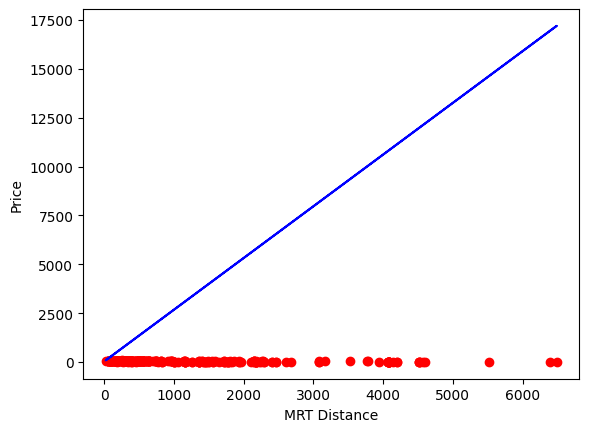

In [ ]:
train_x2=np.asanyarray(train[['MRT_Distance']])
train_y2=np.asanyarray(train[["Price"]])
regr_en.fit(train_x1,train_y1)
print("Coefficient:",regr_en.coef_)
print("Intercept:",regr_en.intercept_)

#plot line into scatter plot
plt.scatter(train.MRT_distance,train.Price,color="red")
plt.plot(train_x2,regr_en.coef_[0][0]*train_x2+regr_en.intercept_[0],'-b')
plt.xlabel("MRT Distance")
plt.ylabel("Price")
plt.show()

In [30]:
test_x2=np.asanyarray(test[["MRT_distance"]])
test_y2=np.asanyarray(test[["Price"]])
test_y2_=regr_en.predict(test_x2)
en_mae2=np.mean(np.absolute(test_y2_ - test_y2))
en_mse2=np.mean((test_y2_ - test_y2)**2)
en_r3=r2_score(test_y2_,test_y2_)
print("Mean absolute error: %.2f" % en_mae2)
print("Residential sum of squares(MSE): %.2f" % en_mse2)
print("R2-score: %.2f" % en_r3)


Mean absolute error: 3027.92
Residential sum of squares(MSE): 23032568.96
R2-score: 1.00


In [31]:
#using model 2 for prediction
new_mrtd=10
pred_en2=regr_en.predict([[new_mrtd]])
print("MRT Distance:%.2f" % (new_mrtd))
print("Predicted House Price: %.2f" % pred_en2[0][0])


MRT Distance:10.00
Predicted House Price: 53.68
